In [ ]:
#problem:Çalışanların şirket içindeki verilerine göre işten ayrılıp ayrılmayacağını tahmin etmek

In [ ]:
import pandas as pd
#veri setini okuyoruz
df = pd.read_csv("veriseti.csv")
print("Veri setinin ilk 5 satırı :")
print(df.head())

Veri setinin ilk 5 satırı :
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours

In [ ]:
print(f"Veri setinin boyutu : {df.shape}")

Veri setinin boyutu : (1470, 35)


In [ ]:
#hedef değişkeni sayıya çeviriyoruz
#1 ayrıldı 0 kaldı
df["Attrition"] = df["Attrition"].map({"Yes":1,"No":0})
#eksik value var mı diye bakıyoruz
print(df.isnull().sum())

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [ ]:
#EDA ve Görselleştirme
import matplotlib.pyplot as plt
print(df[["Age","MonthlyIncome","JobSatisfaction","DistanceFromHome"]].describe())

               Age  MonthlyIncome  JobSatisfaction  DistanceFromHome
count  1470.000000    1470.000000      1470.000000       1470.000000
mean     36.923810    6502.931293         2.728571          9.192517
std       9.135373    4707.956783         1.102846          8.106864
min      18.000000    1009.000000         1.000000          1.000000
25%      30.000000    2911.000000         2.000000          2.000000
50%      36.000000    4919.000000         3.000000          7.000000
75%      43.000000    8379.000000         4.000000         14.000000
max      60.000000   19999.000000         4.000000         29.000000


In [ ]:
print("Ayrılma Durumuna Göre Ortalama Değerler:")
print(df.groupby("Attrition")[["MonthlyIncome","Age","DistanceFromHome"]].mean().round(1))

Ayrılma Durumuna Göre Ortalama Değerler:
           MonthlyIncome   Age  DistanceFromHome
Attrition                                       
0                 6832.7  37.6               8.9
1                 4787.1  33.6              10.6


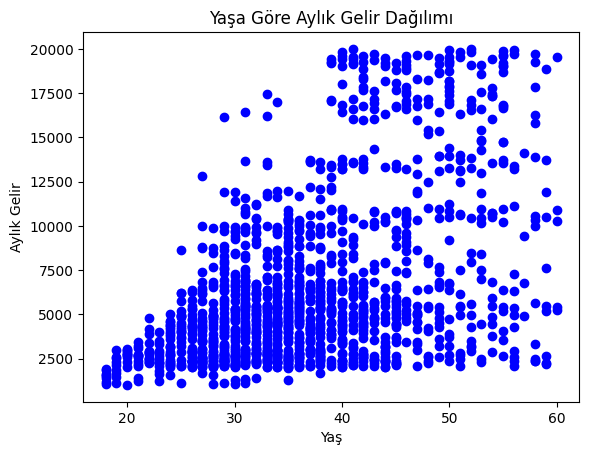

In [ ]:
#aylık gelir dağılım grafiği
plt.scatter(df["Age"],df["MonthlyIncome"],color="blue")
plt.xlabel("Yaş")
plt.ylabel("Aylık Gelir")
plt.title("Yaşa Göre Aylık Gelir Dağılımı")
plt.show()

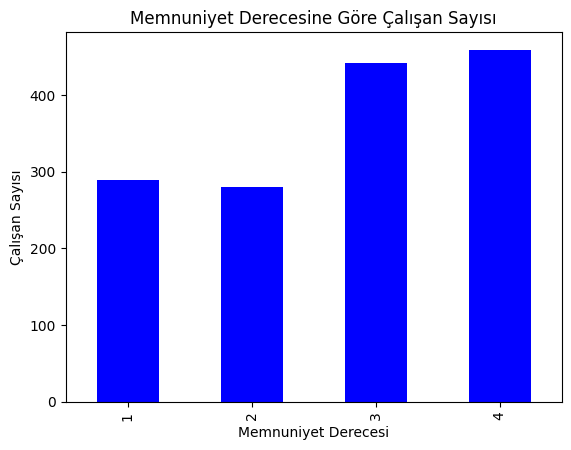

In [ ]:
#iş memnuniyetine göre çalışan sayısı grafiği
df["JobSatisfaction"].value_counts().sort_index().plot(kind="bar",color="blue")
plt.xlabel("Memnuniyet Derecesi")
plt.ylabel("Çalışan Sayısı")
plt.title("Memnuniyet Derecesine Göre Çalışan Sayısı")
plt.show()

Text(0.5, 1.0, 'Maaşa Göre Ayrılma Durumu')

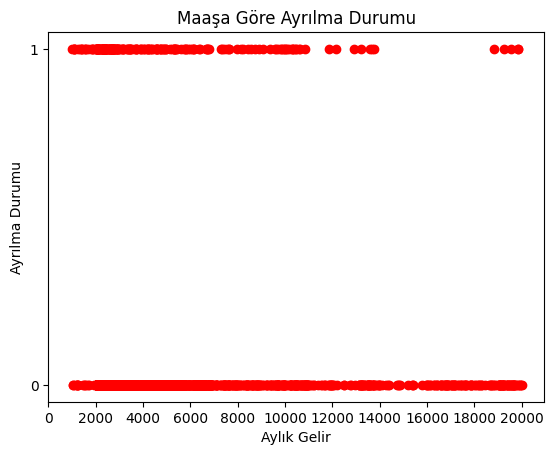

In [ ]:
import numpy as np
plt.scatter(df["MonthlyIncome"],df["Attrition"],color="red")
plt.yticks([0,1]) #y ekseninde sadece 0 ve 1 görünmesini sağlar

plt.xticks(np.arange(0,22000,2000))
plt.xlabel("Aylık Gelir")
plt.ylabel("Ayrılma Durumu")
plt.title("Maaşa Göre Ayrılma Durumu")

In [ ]:
#Gözlemler
#Düşük aylık gelire sahip çalışanların işten ayrılma eğiliminin daha yüksek olduğu gözlemlenmiştir
#Veri setinde genel iş memnuniyeti puanları ortalama 2.7 civarındadır


In [ ]:
#model kurma ve eğitme
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
#özellikler x ,hedef y
x = df[["Age","MonthlyIncome","JobSatisfaction","DistanceFromHome"]]
y = df["Attrition"]

X_train , X_test , y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=42)
print(f"Eğitim seti boyutu : {X_train.shape}")
print(f"Test seti boyutu : {X_test.shape}")


Eğitim seti boyutu : (1176, 4)
Test seti boyutu : (294, 4)


In [ ]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train,y_train)
print("Model Eğitildi")

Model Eğitildi


In [ ]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X_test)
dogruluk = accuracy_score(y_test,y_pred)
print(f"Model doğruluk oranı : {dogruluk*100:.2f}")

Model doğruluk oranı : 81.63


In [ ]:
yeni_ornekler = pd.DataFrame({
    "Age":[25,45,32,20],
    "MonthlyIncome": [2000,12000,4500,5000],
    "JobSatisfaction": [1,4,2,3],
    "DistanceFromHome": [25,2,10,15]
})
yeni_tahminler = model.predict(yeni_ornekler)
sonuc_tablosu = yeni_ornekler.copy()
sonuc_tablosu["Tahmin_Ayrıldı_mı"] = ["Evet(1)" if t==1 else "Hayır(0)" for t in yeni_tahminler]
print(sonuc_tablosu)

   Age  MonthlyIncome  JobSatisfaction  DistanceFromHome Tahmin_Ayrıldı_mı
0   25           2000                1                25           Evet(1)
1   45          12000                4                 2          Hayır(0)
2   32           4500                2                10           Evet(1)
3   20           5000                3                15           Evet(1)


In [ ]:
def calisan_ayrilma_tahmin_etme():
  print("Çalışan İşten Ayrılma Durumu Tahmin Etme")
  try:
    yas = int(input("Çalışanın Yaşı:"))
    gelir = int(input("Aylık Gelir:"))
    memnuniyet = int(input("İş Memnuniyet Derecesi (1-4):"))
    mesafe = int(input("Ev-iş Arası Mesafe:"))

    girdiler = [[yas,gelir,memnuniyet,mesafe]]
    tahmin = model.predict(girdiler)[0]

    if tahmin == 1 :
      print("Sonuç : Çalışanın işten ayrılma olasılığı yüksek")
    else:
      print("Sonuç : Çalışanın işten ayrılma olasılığı düşük")
  except ValueError:
    print("Sayısal değerleri doğru girdiğinizden emin olun ")

calisan_ayrilma_tahmin_etme()

Çalışan İşten Ayrılma Durumu Tahmin Etme
